In [57]:
import pandas as pd 
import matplotlib.pyplot as plt

In [58]:
conditions_df = pd.read_csv('conditions.csv')
oa_df = pd.read_csv('organ_assessments.csv')
patients_df = pd.read_csv('patients.csv')

In [18]:
# 1) What is the distribution of Never, Former and Current smokers ? 
patients_df['smoking_status'].value_counts()
patients_df['smoking_status'].value_counts(normalize=True)*100

smoking_status
Never      45.86
Former     28.26
Current    25.88
Name: proportion, dtype: float64

In [26]:
# 2) What are the average age, bmi, cholesterol, blood pressure and glucose levels?
columns = ['age', 'bmi', 'total_cholesterol_mg_dl', 'systolic_bp_mmhg', 'diastolic_bp_mmhg', 'fasting_glucose_mg_dl']
patients_df[columns].mean().round(2)

age                         49.34
bmi                         27.17
total_cholesterol_mg_dl    193.76
systolic_bp_mmhg           122.36
diastolic_bp_mmhg           78.45
fasting_glucose_mg_dl       99.84
dtype: float64

In [25]:
# 3) How many unique patients are present in each dataset? 
print("Patients Dataset :", patients_df['patient_id'].nunique())
print("Conditions Dataset :", conditions_df['patient_id'].nunique())
print("Organ Assessments Dataset :", oa_df['patient_id'].nunique())

Patients Dataset : 10000
Conditions Dataset : 7693
Organ Assessments Dataset : 10000


In [39]:
# 4) Does every patient have exactly five organ assessments?
organ_count = oa_df.groupby('patient_id')['organ'].nunique()
organ_count[organ_count !=5]

Series([], Name: organ, dtype: int64)

In [41]:
# 5) Are there any duplicate patient-organ combinations?
duplicates = oa_df[oa_df.duplicated(subset=['patient_id', 'organ'], keep=False)]
print(duplicates.shape[0])

0


In [42]:
# 6) Is pack-years calculated consistently without smoking exposure?
patients_df.columns.tolist()
patients_df['calculated_pack_years'] = (
(patients_df['cigarettes_per_day'] / 20) * 
    patients_df['years_smoking']
)
patients_df[['patient_id', 'pack_years', 'calculated_pack_years']].head(10)
(patients_df['pack_years'].round(2) == patients_df['calculated_pack_years'].round(2)).value_counts()

True     8655
False    1345
Name: count, dtype: int64

In [45]:
# 7) How are smoking statuses distributed across gender and age groups?
patients_df['age_group'] = pd.cut(patients_df['age'], bins = [0,29,39,49,59,69,100], 
                                  labels = ['18-29', '30-39', '40-49', '50-59', '60-69', '70+'])

In [46]:
pd.crosstab(patients_df['gender'], patients_df['smoking_status'])

smoking_status,Current,Former,Never
gender,,,
Female,1314,1379,2318
Male,1259,1438,2242
Other,15,9,26


In [47]:
pd.crosstab(patients_df['age_group'], patients_df['smoking_status'])

smoking_status,Current,Former,Never
age_group,,,
18-29,293,315,492
30-39,420,486,704
40-49,600,676,1124
50-59,582,617,1051
60-69,422,471,732
70+,271,261,483


In [48]:
pd.crosstab(patients_df['gender'], patients_df['smoking_status'], normalize='index').mul(100).round(2)

smoking_status,Current,Former,Never
gender,,,
Female,26.22,27.52,46.26
Male,25.49,29.12,45.39
Other,30.00,18.00,52.00


In [49]:
# 8) What percentages of organ assessments fall into Healthy, At risk and Damaged categories for each organ?
organ_status = pd.crosstab(oa_df['organ'], oa_df['simulated_organ_status'], normalize='index')*100 
organ_status.round(2)

simulated_organ_status,At Risk,Damaged,Healthy
organ,,,
Brain,45.27,5.73,49.00
Heart,55.58,15.18,29.24
Kidneys,34.25,1.61,64.14
Liver,25.50,0.23,74.27
Lungs,35.28,13.87,50.85


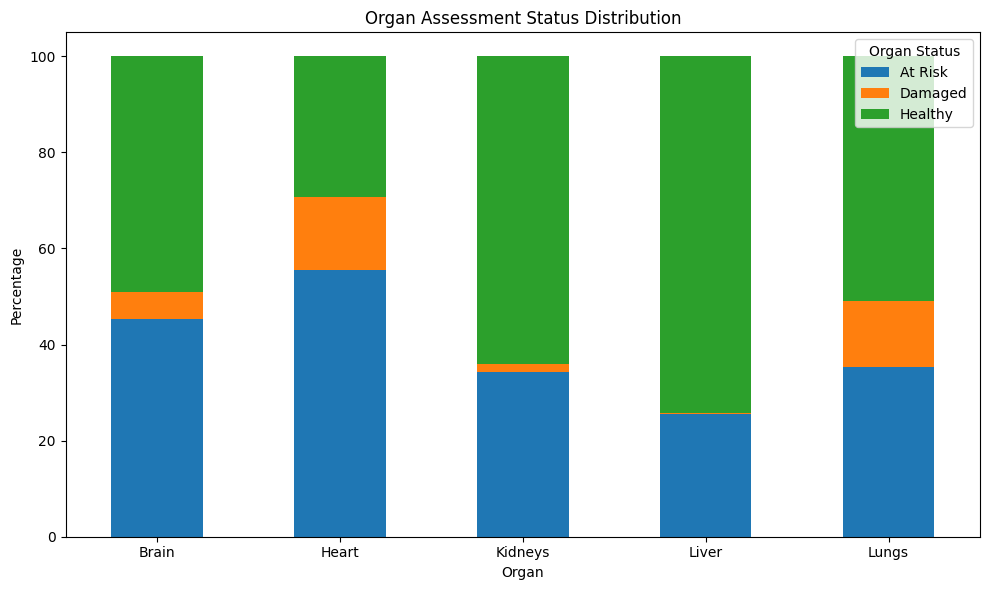

In [56]:
organ_status.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title("Organ Assessment Status Distribution")
plt.xlabel("Organ")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Organ Status")
plt.tight_layout()
plt.show()